# Uber Trip Analysis

Explores 1,156 Uber trip records from 2016 (`UberDataset.csv`): start and end time, category (Business or Personal), start and stop place, miles and purpose.

The notebook cleans the data, adds time features, looks at when and why trips happen, then fits two simple models: a linear regression that predicts trip distance and a KMeans clustering of trips.

> **Date formats:** the file mixes two styles (`01-01-2016 21:11` and `1/13/2016 13:54`). Pandas guesses the format from the first row, which silently turns the rest into missing values, so the notebook parses with `format='mixed'`. Without it only 421 of the trips survive cleaning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load the data

In [2]:
dataset = pd.read_csv("UberDataset.csv")
dataset.head()

,START_DATE,END_DATE,CATEGORY,START,STOP,MILES,PURPOSE
0,01-01-2016 21:11,01-01-2016 21:17,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain
1,01-02-2016 01:25,01-02-2016 01:37,Business,Fort Pierce,Fort Pierce,5.0,NaN
2,01-02-2016 20:25,01-02-2016 20:38,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies
3,01-05-2016 17:31,01-05-2016 17:45,Business,Fort Pierce,Fort Pierce,4.7,Meeting
4,01-06-2016 14:42,01-06-2016 15:49,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit


In [3]:
dataset.shape

(1156, 7)

In [4]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 1156 entries, 0 to 1155
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   START_DATE  1156 non-null   str    
 1   END_DATE    1155 non-null   str    
 2   CATEGORY    1155 non-null   str    
 3   START       1155 non-null   str    
 4   STOP        1155 non-null   str    
 5   MILES       1156 non-null   float64
 6   PURPOSE     653 non-null    str    
dtypes: float64(1), str(6)
memory usage: 63.3 KB


## 2. Clean the data

- `PURPOSE` is empty for about half the trips, so empty values become `"NOT"` (not recorded).
- Convert the start and end times to real dates.
- Add the hour of the day and group it into Morning (up to 10:59), Afternoon (11:00–15:59), Evening (16:00–19:59) and Night (20:00 onwards).
- Drop rows with missing values and duplicates.

In [5]:
dataset['PURPOSE'] = dataset['PURPOSE'].fillna("NOT")

In [6]:
dataset['START_DATE'] = pd.to_datetime(dataset['START_DATE'], 
                                       format='mixed', errors='coerce')
dataset['END_DATE'] = pd.to_datetime(dataset['END_DATE'], 
                                     format='mixed', errors='coerce')

In [7]:
from datetime import datetime

dataset['date'] = pd.DatetimeIndex(dataset['START_DATE']).date
dataset['time'] = pd.DatetimeIndex(dataset['START_DATE']).hour

#changing into categories of day and night
dataset['day-night'] = pd.cut(x=dataset['time'],
                              bins = [0,10,15,19,24],
                              labels = ['Morning','Afternoon','Evening','Night'],
                              include_lowest=True)  # include hour 0, which would otherwise become NaN

In [8]:
dataset.head()

,START_DATE,END_DATE,CATEGORY,START,STOP,MILES,PURPOSE,date,time,day-night
0,2016-01-01 21:11:00,2016-01-01 21:17:00,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain,2016-01-01,21.0,Night
1,2016-01-02 01:25:00,2016-01-02 01:37:00,Business,Fort Pierce,Fort Pierce,5.0,NOT,2016-01-02,1.0,Morning
2,2016-01-02 20:25:00,2016-01-02 20:38:00,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies,2016-01-02,20.0,Night
3,2016-01-05 17:31:00,2016-01-05 17:45:00,Business,Fort Pierce,Fort Pierce,4.7,Meeting,2016-01-05,17.0,Evening
4,2016-01-06 14:42:00,2016-01-06 15:49:00,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit,2016-01-06,14.0,Afternoon


In [9]:
dataset.dropna(inplace=True)

In [10]:
dataset.drop_duplicates(inplace=True)

## 3. Explore: category, time of day and purpose

In [11]:
object_cols = list(dataset.select_dtypes(include=['object', 'string']).columns)

unique_values = {}
for col in object_cols:
  unique_values[col] = dataset[col].unique().size
unique_values


{'CATEGORY': 2, 'START': 177, 'STOP': 188, 'PURPOSE': 11, 'date': 294}

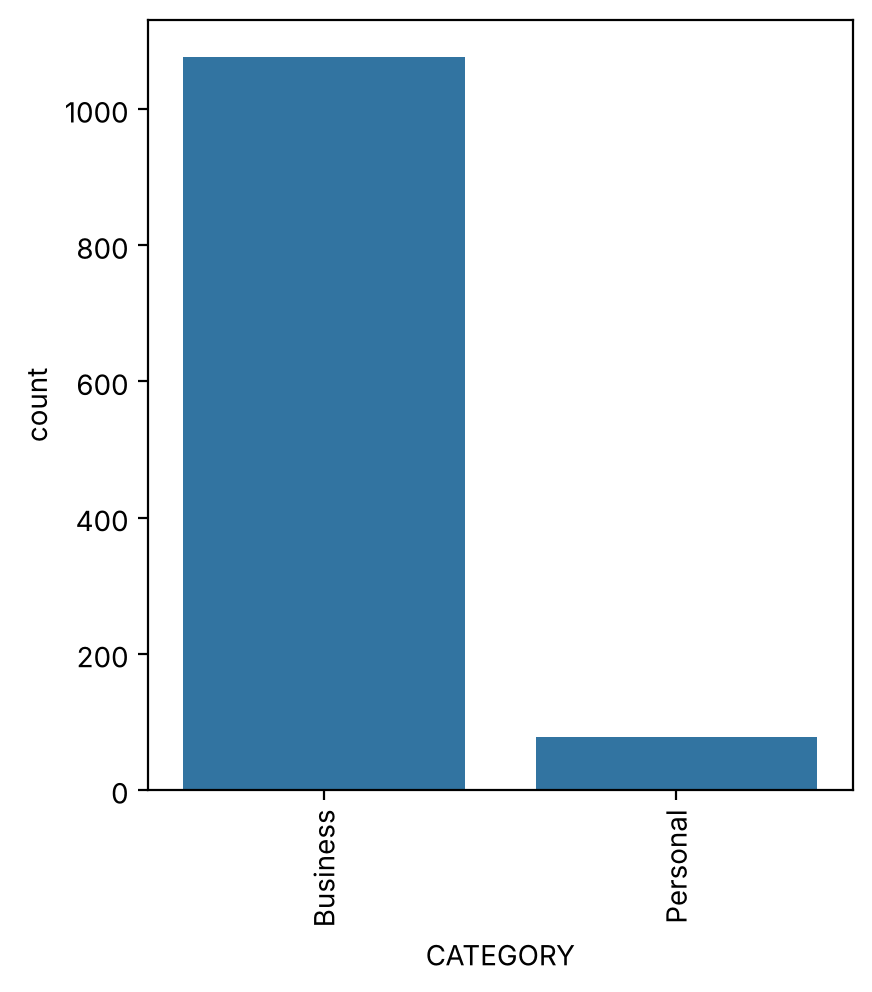

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

# First subplot
plt.subplot(1, 2, 1)
sns.countplot(x='CATEGORY', data=dataset)
plt.xticks(rotation=90)

# Continue with other plots if needed
plt.show()


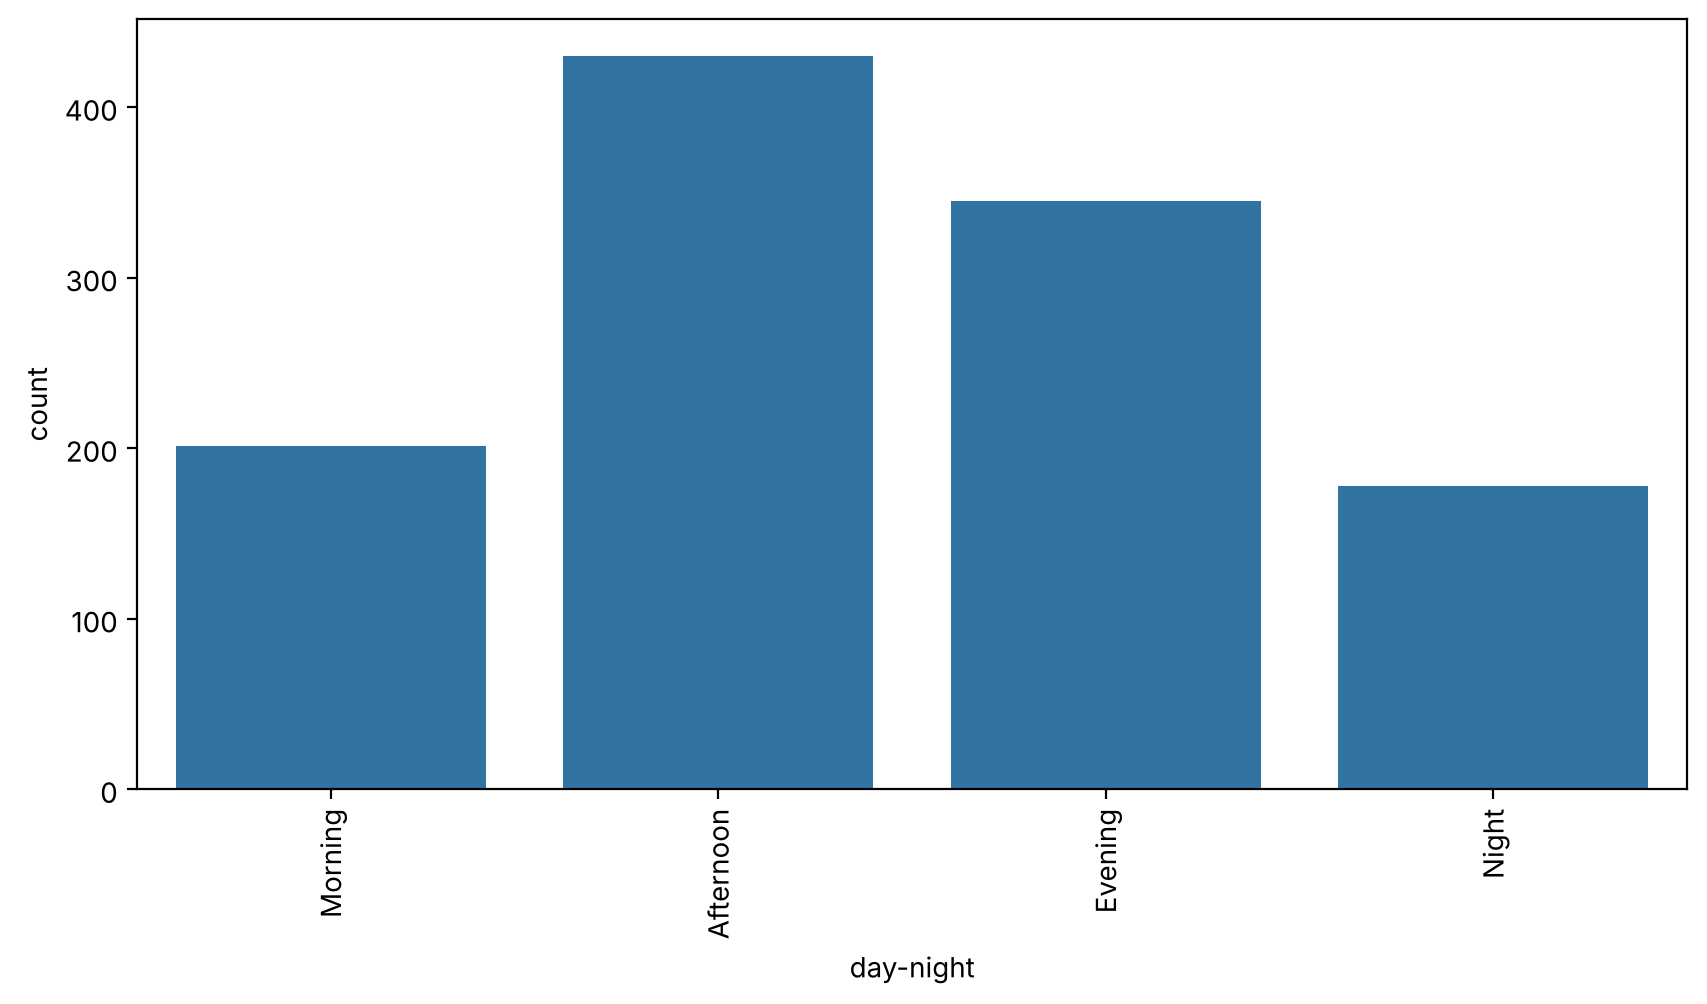

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

# Creating a countplot for 'day-night' column
sns.countplot(x='day-night', data=dataset)
plt.xticks(rotation=90)

plt.show()

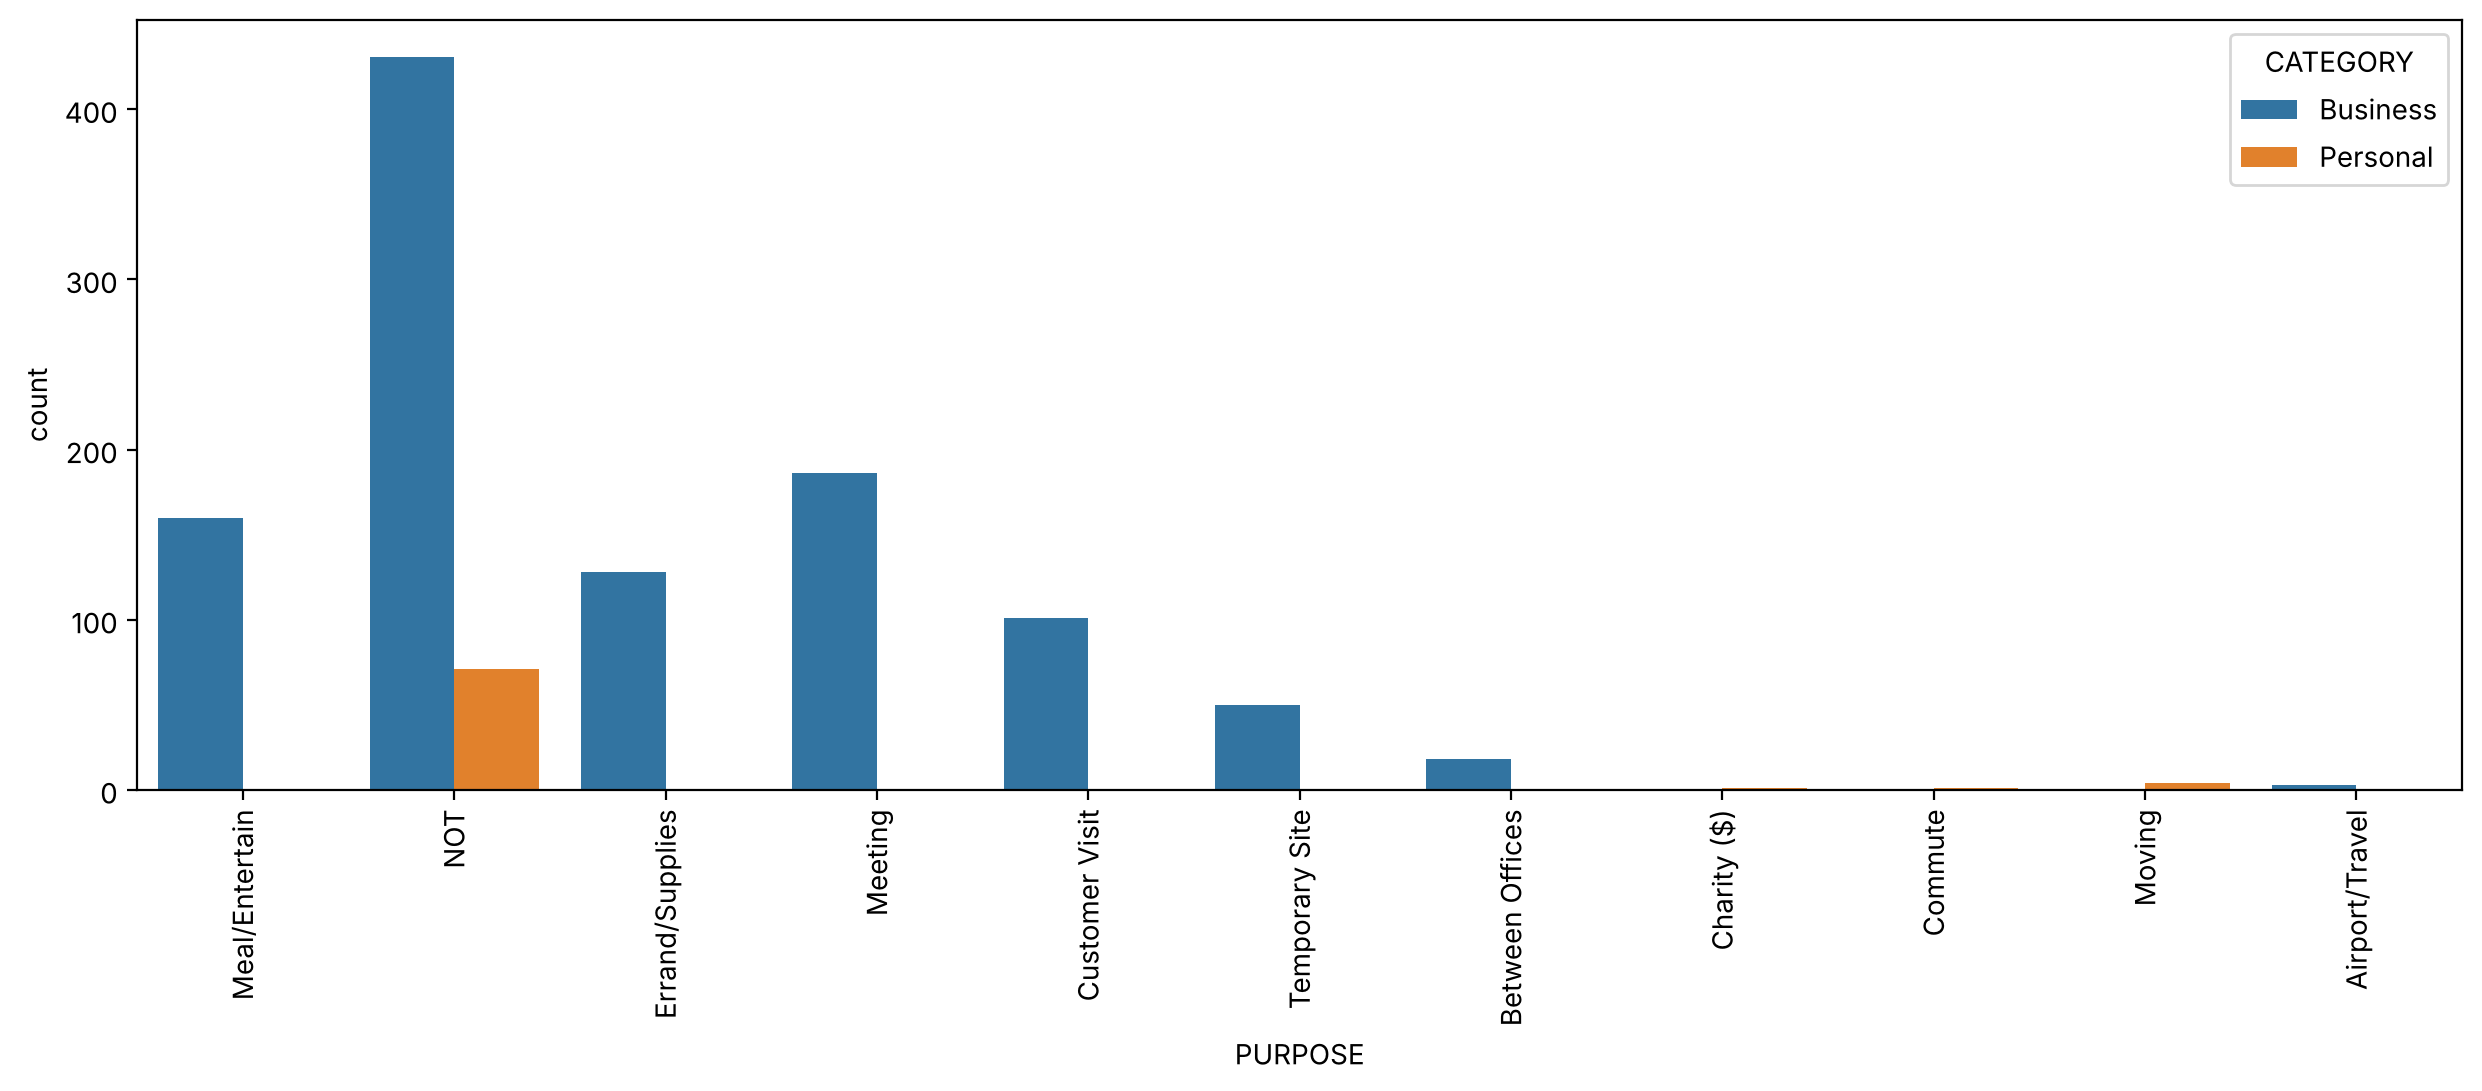

In [14]:
plt.figure(figsize=(15, 5))
sns.countplot(data=dataset, x='PURPOSE', hue='CATEGORY')
plt.xticks(rotation=90)
plt.show()

## 4. Encode the categories and look at correlations

In [15]:
from sklearn.preprocessing import OneHotEncoder
object_cols = ['CATEGORY', 'PURPOSE']
OH_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
OH_cols = pd.DataFrame(OH_encoder.fit_transform(dataset[object_cols]))
OH_cols.index = dataset.index
OH_cols.columns = OH_encoder.get_feature_names_out()
df_final = dataset.drop(object_cols, axis=1)
dataset = pd.concat([df_final, OH_cols], axis=1)

<Axes: >

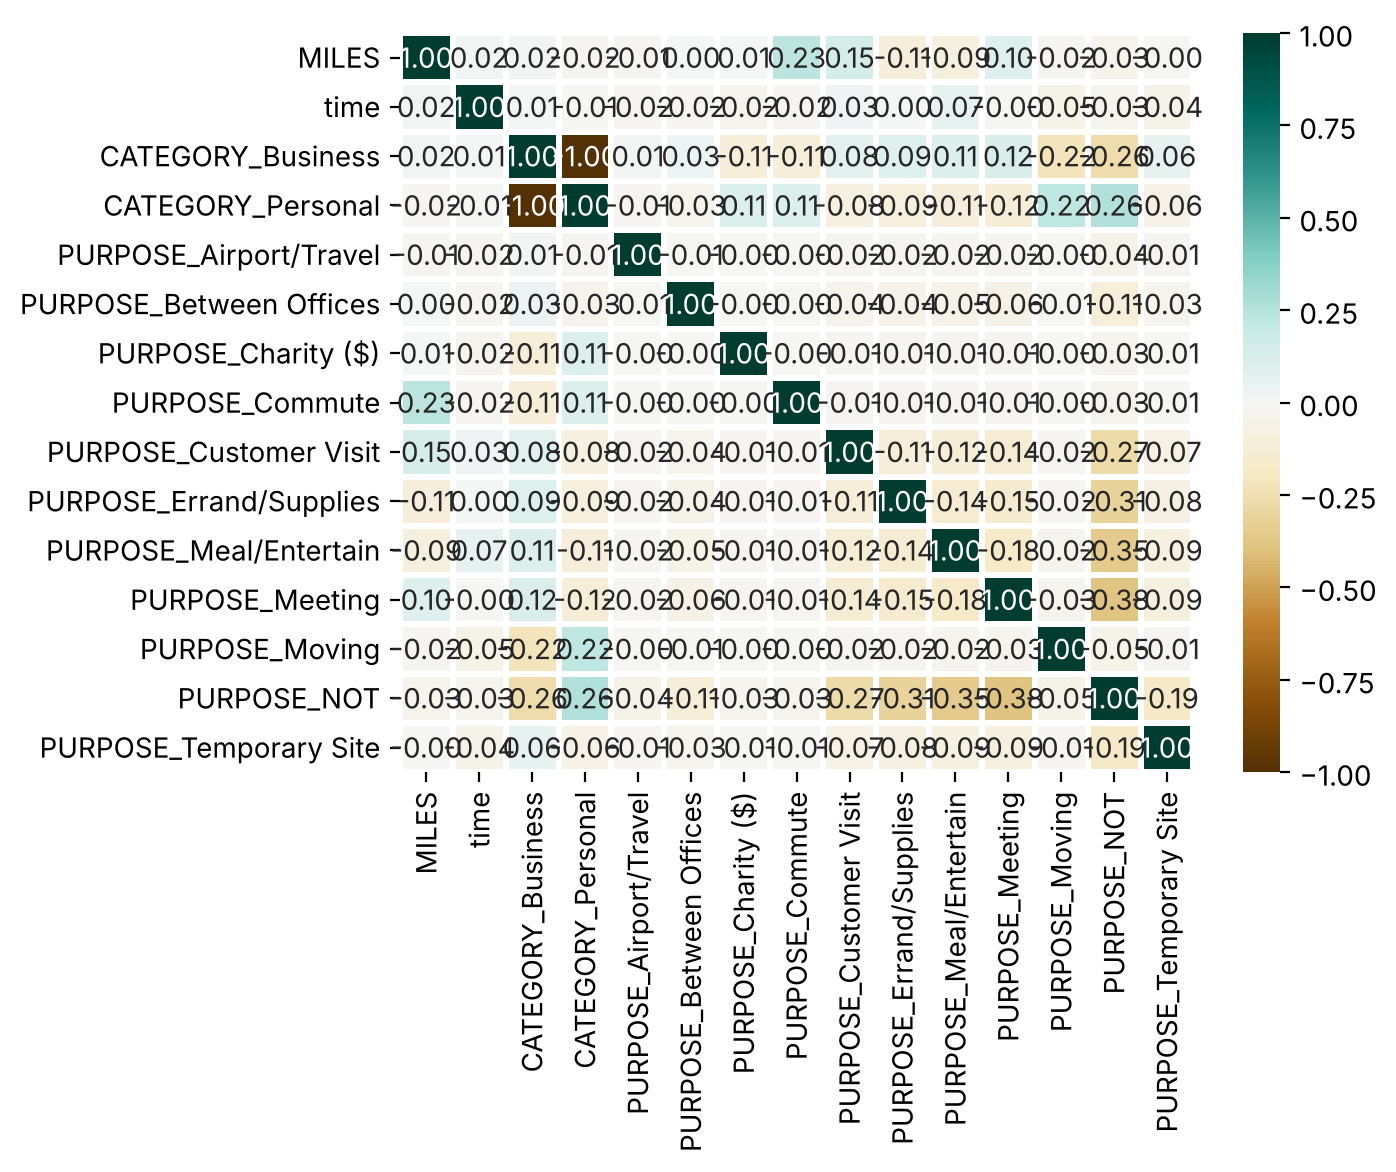

In [16]:
# Select only numerical columns for correlation calculation
numeric_dataset = dataset.select_dtypes(include=['number'])

sns.heatmap(numeric_dataset.corr(), 
            cmap='BrBG', 
            fmt='.2f', 
            linewidths=2, 
            annot=True)


## 5. When do trips happen?

Trips per month and per day of the week.

[Text(0.5, 0, 'MONTHS'), Text(0, 0.5, 'VALUE COUNT')]

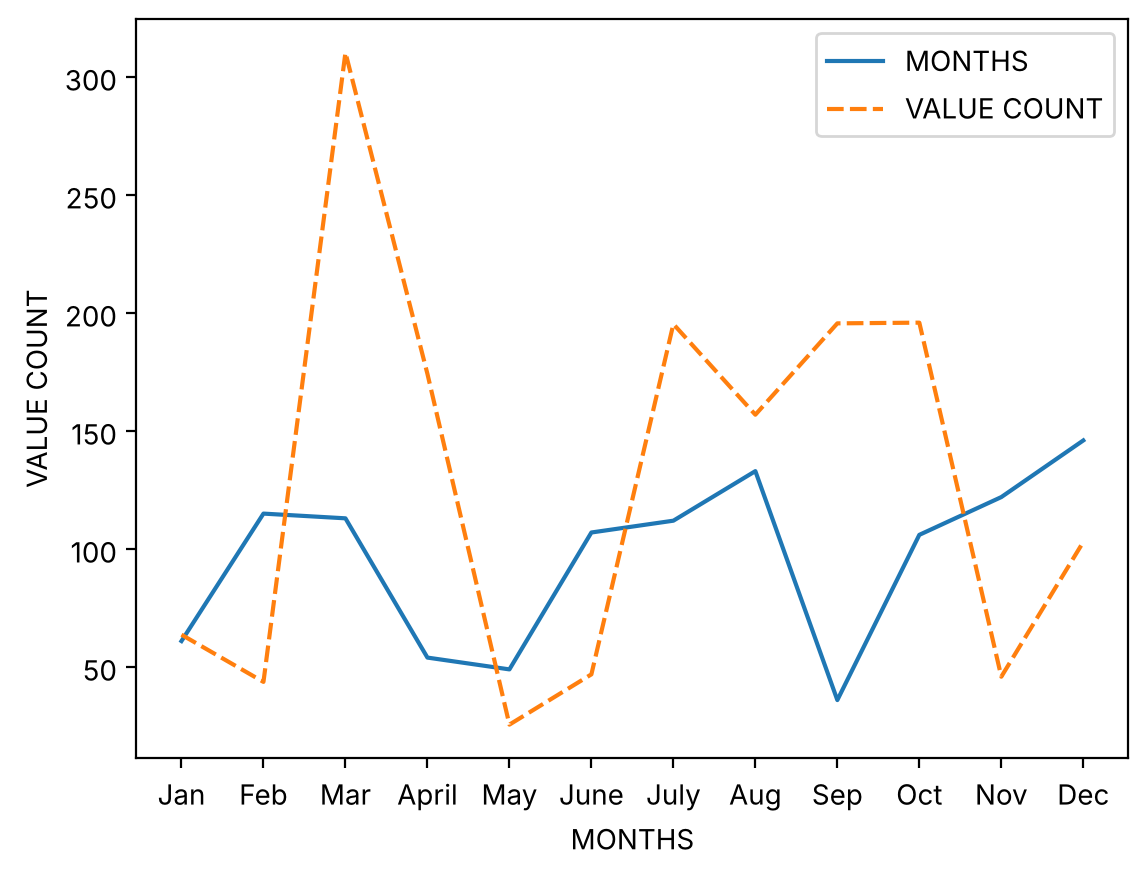

In [17]:
dataset['MONTH'] = pd.DatetimeIndex(dataset['START_DATE']).month
month_label = {1.0: 'Jan', 2.0: 'Feb', 3.0: 'Mar', 4.0: 'April',
               5.0: 'May', 6.0: 'June', 7.0: 'July', 8.0: 'Aug',
               9.0: 'Sep', 10.0: 'Oct', 11.0: 'Nov', 12.0: 'Dec'}
dataset["MONTH"] = dataset.MONTH.map(month_label)

mon = dataset.MONTH.value_counts(sort=False)

# Month total rides count vs Month ride max count
df = pd.DataFrame({"MONTHS": mon.values,
                   "VALUE COUNT": dataset.groupby('MONTH',
                                                  sort=False)['MILES'].max()})

p = sns.lineplot(data=df)
p.set(xlabel="MONTHS", ylabel="VALUE COUNT")


In [18]:
dataset['DAY'] = dataset.START_DATE.dt.weekday
day_label = {
    0: 'Mon', 1: 'Tues', 2: 'Wed', 3: 'Thus', 4: 'Fri', 5: 'Sat', 6: 'Sun'
}
dataset['DAY'] = dataset['DAY'].map(day_label)

Text(0, 0.5, 'COUNT')

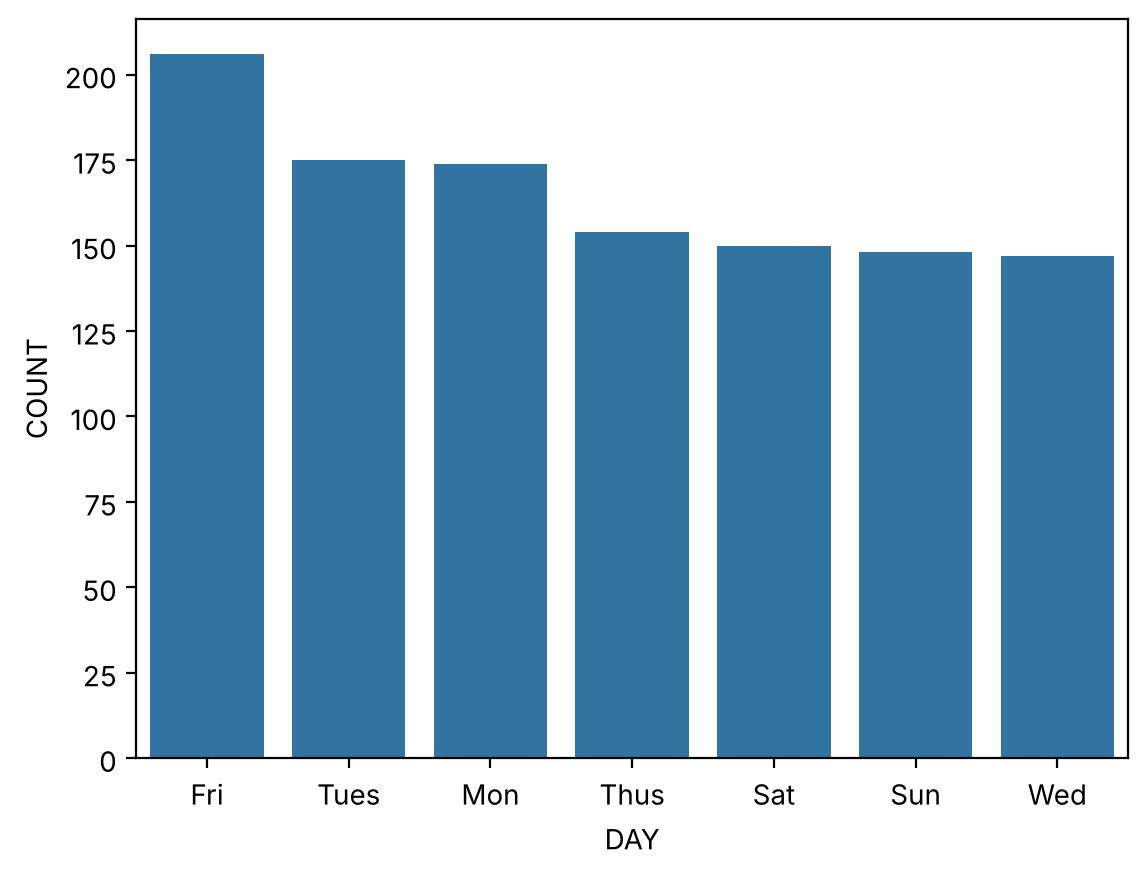

In [19]:
day_label = dataset.DAY.value_counts()
sns.barplot(x=day_label.index, y=day_label);
plt.xlabel('DAY')
plt.ylabel('COUNT')

## 6. How far do trips go?

Box plots and a histogram of `MILES`. A few very long trips stretch the first plot, so the later ones zoom in on trips under 100 and 40 miles.

<Axes: ylabel='MILES'>

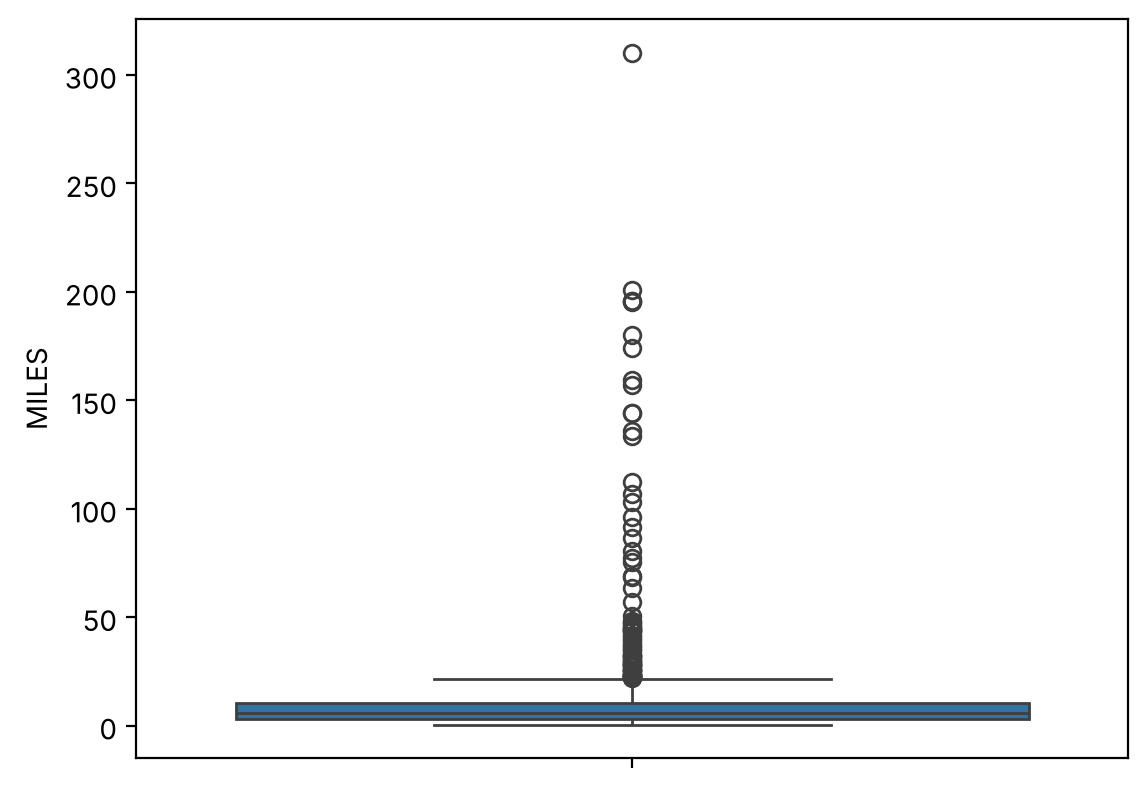

In [20]:
sns.boxplot(dataset['MILES'])

<Axes: ylabel='MILES'>

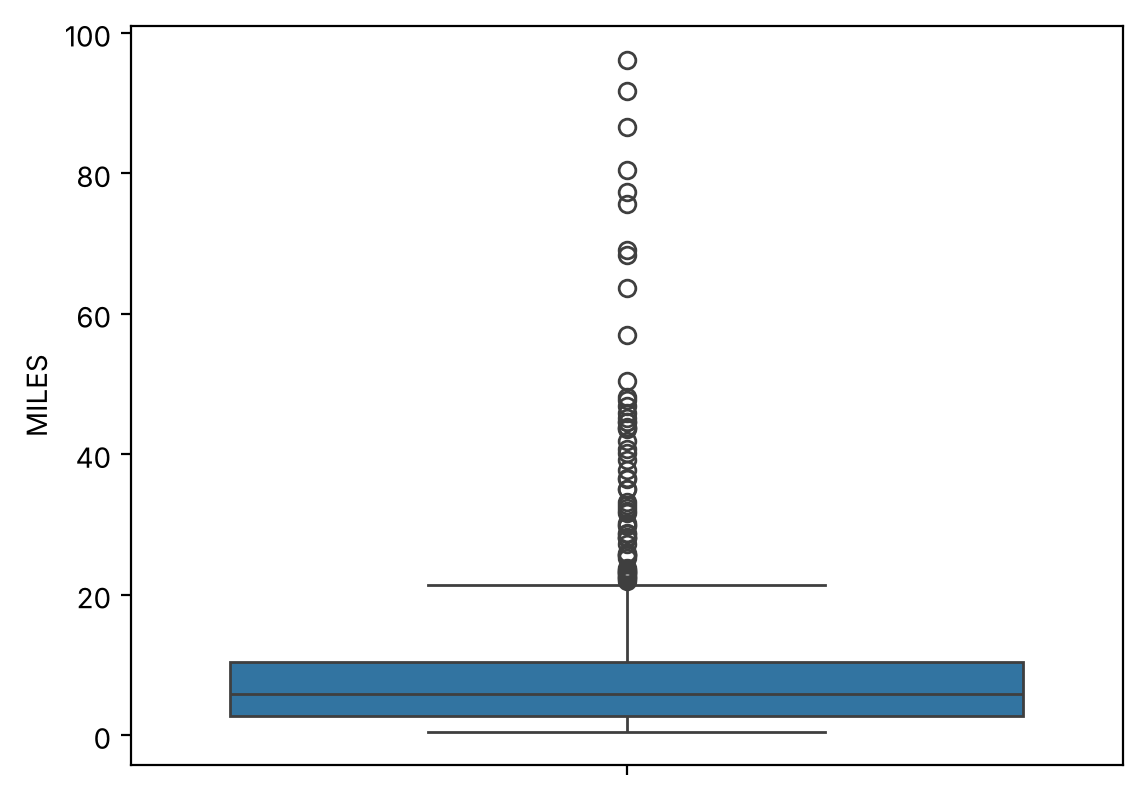

In [21]:
sns.boxplot(dataset[dataset['MILES']<100]['MILES'])

<Axes: xlabel='MILES', ylabel='Count'>

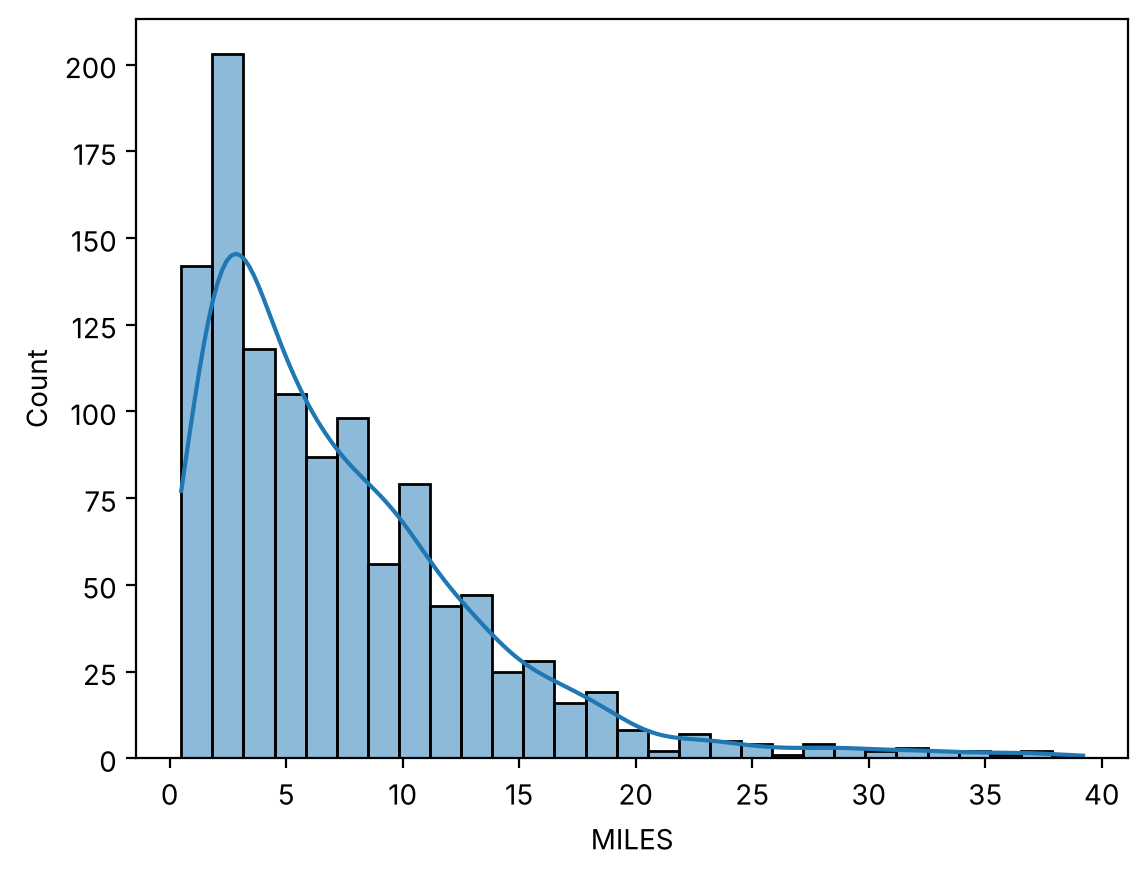

In [22]:
sns.histplot(dataset[dataset['MILES']<40]['MILES'], kde=True)

## 7. Model: predict trip distance

A linear regression predicts `MILES` from the trip's duration and category (one-hot encoded), using an 80/20 train/test split.

In [23]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Load dataset
data = pd.read_csv('UberDataset.csv')

# Data cleaning and preprocessing
data_cleaned = data.dropna(subset=['END_DATE', 'CATEGORY'])
data_cleaned['START_DATE'] = pd.to_datetime(data_cleaned['START_DATE'], format='mixed', errors='coerce')
data_cleaned['END_DATE'] = pd.to_datetime(data_cleaned['END_DATE'], format='mixed', errors='coerce')
data_cleaned['DURATION'] = (data_cleaned['END_DATE'] - data_cleaned['START_DATE']).dt.total_seconds() / 60.0
data_cleaned = data_cleaned.dropna(subset=['START_DATE', 'END_DATE', 'DURATION'])

# Features and target
X = data_cleaned[['CATEGORY', 'DURATION']]
y = data_cleaned['MILES']

# Preprocessing and model pipeline
preprocessor = ColumnTransformer(transformers=[('cat', OneHotEncoder(), ['CATEGORY'])], remainder='passthrough')
pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', LinearRegression())])

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Train and evaluate
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")
'''This code is designed to predict the distance (in miles) of Uber trips based on their category and duration using a linear regression model'''

Mean Squared Error: 217.90839019962357
R-squared: 0.7501115226298655


'This code is designed to predict the distance (in miles) of Uber trips based on their category and duration using a linear regression model'

## 8. Cluster trips by distance and duration

KMeans with 3 clusters on standardized miles and duration.

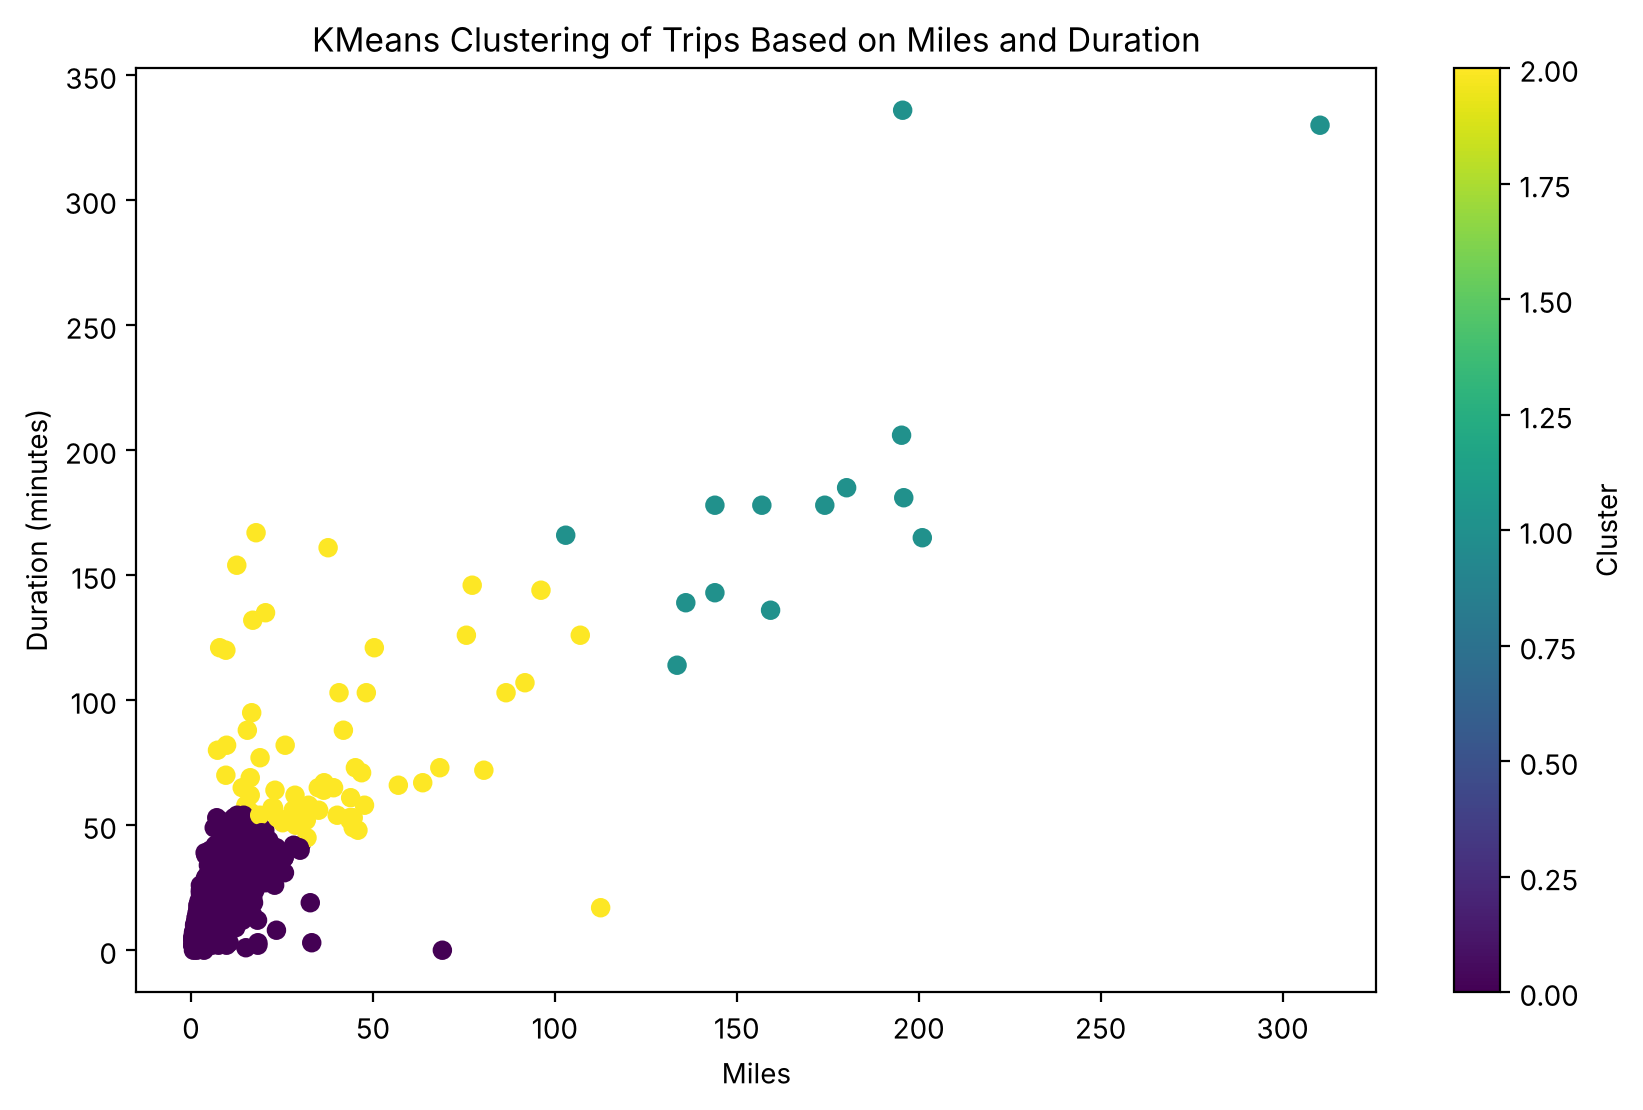

'This code performs KMeans clustering on an Uber dataset to categorize trips based on the miles traveled and the trip duration'

In [24]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Load the dataset
data = pd.read_csv('UberDataset.csv')

# Data cleaning and preprocessing
data_cleaned = data.dropna(subset=['END_DATE', 'CATEGORY'])
data_cleaned['START_DATE'] = pd.to_datetime(data_cleaned['START_DATE'], format='mixed', errors='coerce')
data_cleaned['END_DATE'] = pd.to_datetime(data_cleaned['END_DATE'], format='mixed', errors='coerce')
data_cleaned['DURATION'] = (data_cleaned['END_DATE'] - data_cleaned['START_DATE']).dt.total_seconds() / 60.0
data_cleaned = data_cleaned.dropna(subset=['START_DATE', 'END_DATE', 'DURATION'])

# Selecting features for clustering
X_clustering = data_cleaned[['MILES', 'DURATION']]

# Standardize features for better clustering performance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clustering)

# Apply KMeans clustering
kmeans = KMeans(n_clusters=3, random_state=0)
data_cleaned['Cluster'] = kmeans.fit_predict(X_scaled)

# Plotting the clusters
plt.figure(figsize=(10, 6))
plt.scatter(data_cleaned['MILES'], data_cleaned['DURATION'], c=data_cleaned['Cluster'], cmap='viridis')
plt.xlabel('Miles')
plt.ylabel('Duration (minutes)')
plt.title('KMeans Clustering of Trips Based on Miles and Duration')
plt.colorbar(label='Cluster')
plt.show()
'''This code performs KMeans clustering on an Uber dataset to categorize trips based on the miles traveled and the trip duration'''


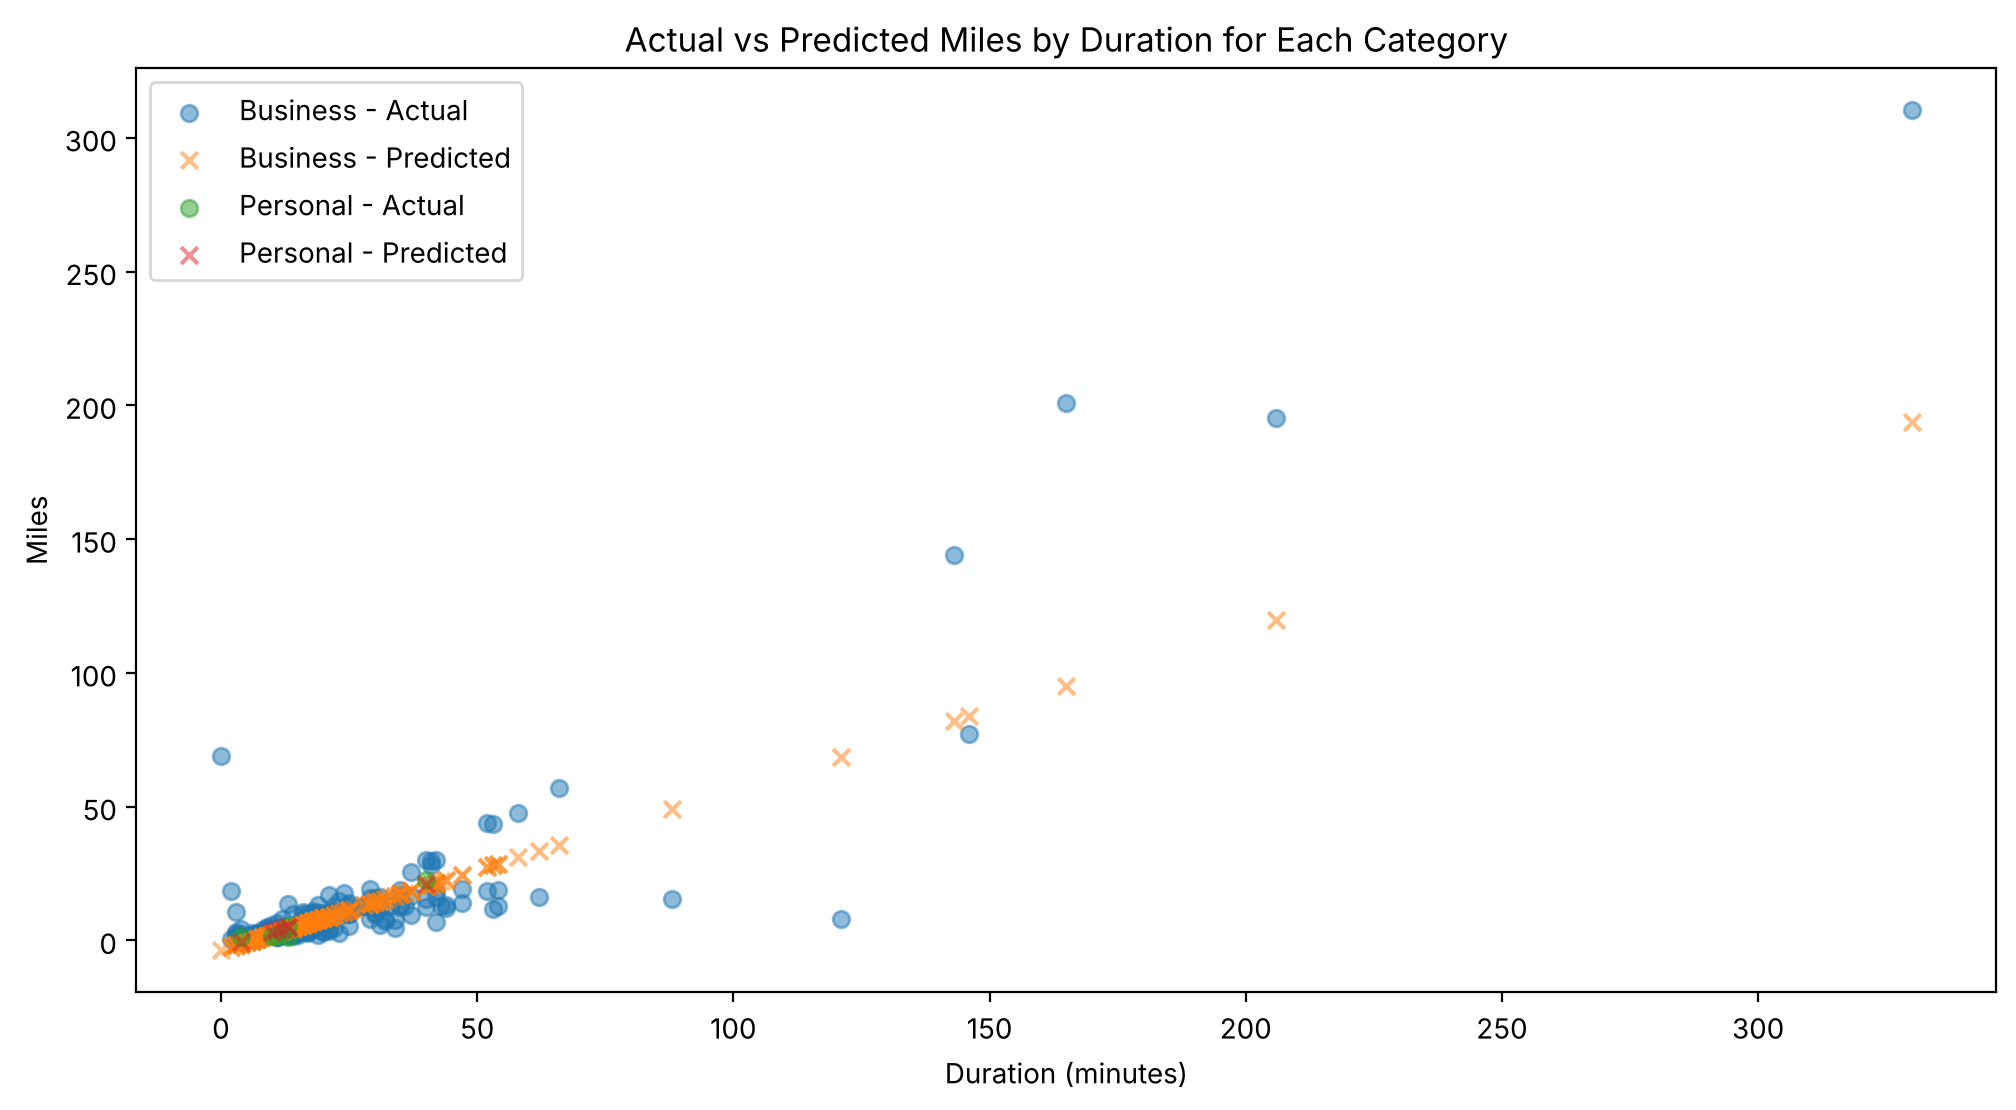

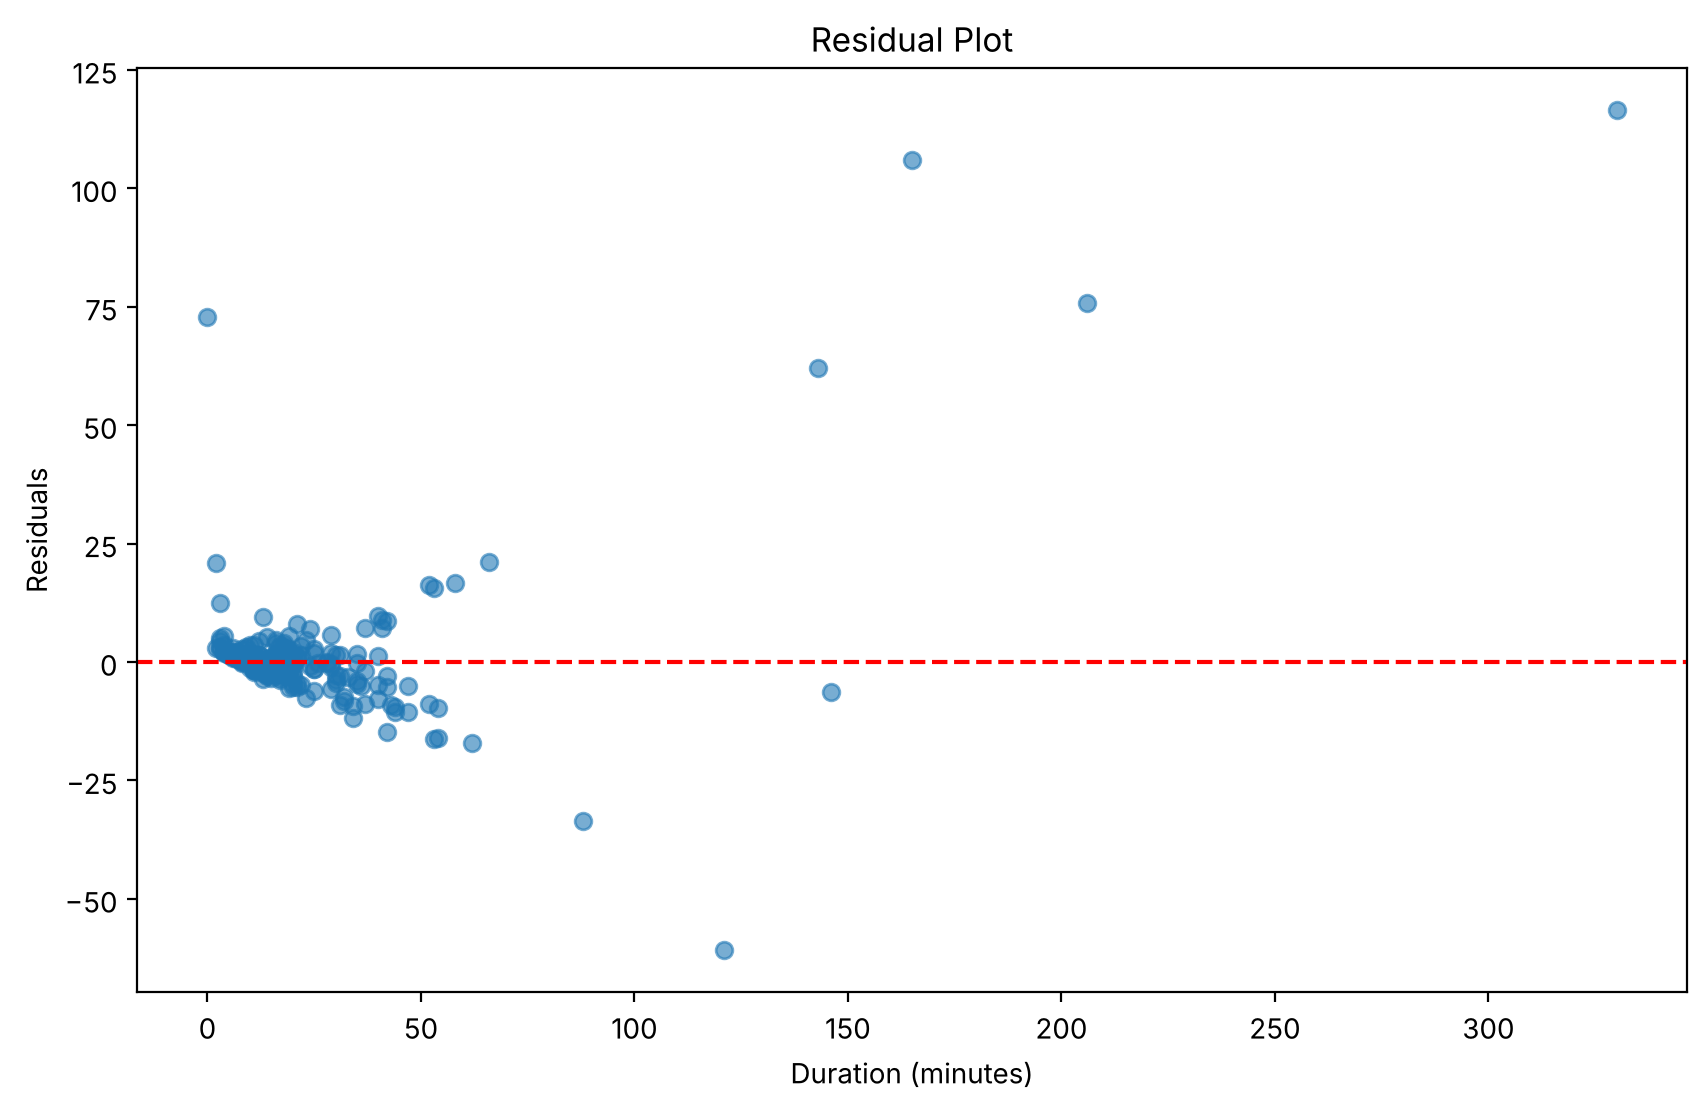

In [25]:
import matplotlib.pyplot as plt

# Generate predictions for the test set
y_pred = pipeline.predict(X_test)

# Plot predictions vs actual values for each CATEGORY
categories = X_test['CATEGORY'].unique()
plt.figure(figsize=(12, 6))

for category in categories:
    # Filter data for each category
    category_mask = X_test['CATEGORY'] == category
    duration_category = X_test[category_mask]['DURATION']
    actual_miles = y_test[category_mask]
    predicted_miles = y_pred[category_mask]

    # Plot actual vs predicted for each category
    plt.scatter(duration_category, actual_miles, label=f'{category} - Actual', alpha=0.5)
    plt.scatter(duration_category, predicted_miles, label=f'{category} - Predicted', alpha=0.5, marker='x')

# Add labels and legend
plt.xlabel('Duration (minutes)')
plt.ylabel('Miles')
plt.title('Actual vs Predicted Miles by Duration for Each Category')
plt.legend()
plt.show()

# Residual Plot
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(X_test['DURATION'], residuals, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Duration (minutes)')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

## Summary of what the data shows

- **Data used:** 1,154 trips across 12 months and 294 different days after cleaning.
- **Category:** 1,077 Business trips (93%) versus 77 Personal.
- **Time of day:** Afternoon is busiest (430), then Evening (345), Morning (201) and Night (178).
- **Purpose** (about 44% of trips have none recorded): Meeting (186), Meal/Entertain (160), Errand/Supplies (128), Customer Visit (101).
- **Calendar:** December has the most trips (146) and September the fewest (36). Friday is the busiest weekday (206).
- **Distance:** median 6 miles, mean 10.6; 96.5% of trips are under 40 miles, the longest is 310.3.
- **Linear regression** (category and duration → miles): R² = 0.75, mean squared error = 217.9 (an error of about 15 miles). Duration alone carries most of the signal.
- **KMeans (3 clusters):** **1079** trips averaging 7 miles and 18 minutes; **62** trips averaging 38 miles and 80 minutes; **14** trips averaging 174 miles and 188 minutes.

These are descriptive results on one small dataset, not a general statement about Uber trips.